In [228]:
%matplotlib inline
from Gaussian_Quadrature import gauss_radau_left
import matplotlib.pyplot as plt
import scipy as sp
import numpy as np
from scipy import linalg, interpolate, integrate
from IPython.display import clear_output
from scipy.integrate import solve_ivp
from scipy.interpolate import BarycentricInterpolator
from scipy.optimize import minimize
from scipy.linalg import solve_continuous_are
from numpy.polynomial.legendre import leggauss
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as CK, WhiteKernel
import warnings

In [229]:
n_states = 3
n_inputs = 1
n_outputs = 1

In [230]:
beta = 20.0 

# The Full-Order Model (FOM) is defined by
# dx/dt = Ax + Bu + einsum('ijk,j,k', H, x, x) + einsum('i, ijk, k', N, u, x)
# y = Cx

## linear part of FOM
A_FOM = np.array([[-1.0, 0.0, 0.0], \
                  [0.0, -2.0, 0.0], \
                  [0.0, 0.0, -5.0]])

B_FOM = np.array([[1.0], \
                  [1.0], \
                  [1.0]])

C_FOM = np.array([[1.0, 1.0, 1.0]])

## nonlinear part of FOM
H_FOM = np.zeros((n_states, n_states, n_states))
H_FOM[0, 0, 2] = beta
H_FOM[1, 1, 2] = beta

# symmetrize the quadratic term
H_FOM = (H_FOM + np.transpose(H_FOM, axes=(0,2,1))) / 2.0

N_FOM = np.zeros((n_states, n_inputs, n_states))

# full-order model
def FOM(x, u):
    f = np.einsum('ij,...j', A_FOM, x) + np.einsum('ij,...j', B_FOM, u) + \
        np.einsum('ijk,...j,...k', H_FOM, x, x) + np.einsum('ijk,...j,...k', N_FOM, u, x)
    return f

# observation function
def FOM_obs(x):
    g = np.einsum('ij,...j', C_FOM, x)
    return g

# derivative of full-order model acting on v
def d_FOM(x, u, v):
    df_v = np.einsum('ij,...j', A_FOM, v) + \
        2.0*np.einsum('ijk,...j,...k', H_FOM, x, v) + np.einsum('ijk,...j,...k', N_FOM, u, v)
    return df_v

# derivative of observation function acting on v
def d_FOM_obs(x, v):
    dg_v = np.einsum('ij,...j', C_FOM, v)
    return dg_v

# adjoint of FOM acting on w
def d_FOM_adj(x, u, w):
    df_T_w = np.einsum('ji,...j', A_FOM, w) + \
        2.0*np.einsum('kji,...j,...k', H_FOM, x, w) + np.einsum('kji,...j,...k', N_FOM, u, w)
    return df_T_w

# adjoint of observations acting on w
def d_FOM_obs_adj(x, w):
    dg_T_w = np.einsum('ji,...j', C_FOM, w)
    return dg_T_w

In [231]:
# step size for finite differences
eps = 1.0e-8

# random state and input
x = np.random.randn(n_states)
u = np.random.randn(n_inputs)

# random vector tangent to state
v = np.random.randn(n_states)

# validate derivative of FOM and observation function
df_v_FD = (FOM(x+eps*v,u) - FOM(x,u))/eps
df_v = d_FOM(x,u,v)
print(f"Relative error for FOM derivative: {np.linalg.norm(df_v - df_v_FD) / np.linalg.norm(df_v_FD):.3e}")

dg_v_FD = (FOM_obs(x+eps*v) - FOM_obs(x))/eps
dg_v = d_FOM_obs(x,v)
print(f"Relative error for observation derivative: {np.linalg.norm(dg_v - dg_v_FD) / np.linalg.norm(dg_v_FD):.3e}")

# random vector tangent to state
w = np.random.randn(n_states)

# validate adjoint of derivative of FOM using definition of adjoint
IP1 = np.dot(d_FOM(x,u,v), w)
IP2 = np.dot(v, d_FOM_adj(x,u,w))
print(f"Adjoint consistency check for FOM derivative: {np.linalg.norm(IP2 - IP1)/np.linalg.norm(IP1):.3e}")

# random vector tangent to output
w = np.random.randn(n_outputs)

# validate adjoint of derivative of observation function using definition of adjoint
IP1 = np.dot(d_FOM_obs(x,v), w)
IP2 = np.dot(v, d_FOM_obs_adj(x,w))
print(f"Adjoint consistency check for observation derivative: {np.linalg.norm(IP2 - IP1)/np.linalg.norm(IP1):.3e}")

Relative error for FOM derivative: 3.906e-09
Relative error for observation derivative: 7.054e-09
Adjoint consistency check for FOM derivative: 0.000e+00
Adjoint consistency check for observation derivative: 0.000e+00


In [232]:
# ORIGINAL SET OF INITIAL CONDITION
# set tolerance for solvers
atol = 1.0e-9
rtol = 1.0e-7
solver_method = 'RK45'

In [233]:
# number of trajectories
np.random.seed(24)
n_traj = 2
traj_ICs = np.array([np.random.uniform(0.5, 1.0, size=n_states) for _ in range(n_traj)])

In [234]:
# # Plot the initial conditions
# fig = plt.figure()
# ax = fig.add_subplot(111, projection='3d')

# ax.scatter(traj_ICs[:, 0], traj_ICs[:, 1], traj_ICs[:, 2])
# ax.set_xlabel('x_1(0)')
# ax.set_ylabel('x_2(0)')
# ax.set_zlabel('x_3(0)')
# ax.set_title('Training initial conditions for the toy model')

# plt.show()

In [235]:
# Create a common time grid and zero-control input for each trajectory.
# The model is simulated over the interval [0, 10] with 1001 time points.
traj_time = np.linspace(0, 10.0, 1001)  # 1000 time steps

# Use zero control input for all trajectories.
u_trajs = [np.reshape(0.0 * traj_time, (-1, 1)) for k in range(n_traj)]

# Alternative control choices for testing:
# u_trajs = [np.reshape(np.sin(traj_time), (-1, 1)) for k in range(n_traj)]
# u_trajs = [np.ones((len(traj_time), 1)) for k in range(n_traj)]

# Storage arrays for the simulated state and output trajectories.
FOM_x_trajs = [_ for _ in range(n_traj)]
FOM_y_trajs = [_ for _ in range(n_traj)]

In [236]:
for k in range(n_traj):
    # interpolate the input
    u_fun = sp.interpolate.interp1d(traj_time, u_trajs[k], axis=0)
    
    # initial condition
    x0 = traj_ICs[k]
    
    # simulate the FOM
    sol = sp.integrate.solve_ivp(lambda t,x: FOM(x, u_fun(t)), \
                                 # jac = lambda t,x: d_FOM(x, u_fun(t), np.eye(n_states)), \
                                 t_span = [traj_time[0], traj_time[-1]], \
                                 y0 = x0, \
                                 t_eval = traj_time, \
                                 method = solver_method, \
                                 atol=atol, rtol=rtol)
    
    # This overwrites the stored state and output trajectories for each new initial condition.
    FOM_x_trajs[k] = sol.y.T
    FOM_y_trajs[k] = FOM_obs(sol.y.T)

In [237]:
# This keeps every 100th time point for downsampling trajectories.
sample = 100
t_data = traj_time[::sample]
y_traj_data = [FOM_y_trajs[k][::sample, :] for k in range(n_traj)]
x_traj_data = [FOM_x_trajs[k][::sample, :] for k in range(n_traj)]

In [238]:
# Insert the trajectory number to be plotted
k = 0

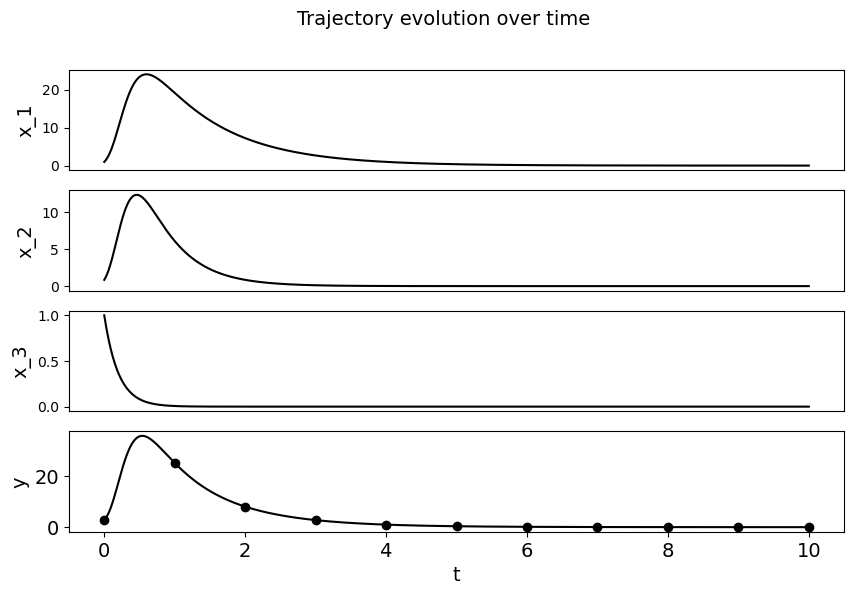

In [239]:
fig = plt.figure(figsize=(10,6))
fig.suptitle('Trajectory evolution over time', fontsize=14)
ax = fig.add_subplot(4,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], 'k-')
ax.set_ylabel('x_1', fontsize=14)
ax.set_xticks([])

ax = fig.add_subplot(4,1,2)
ax.plot(traj_time, FOM_x_trajs[k][:,1], 'k-')
ax.set_ylabel('x_2', fontsize=14)
ax.set_xticks([])

ax = fig.add_subplot(4,1,3)
ax.plot(traj_time, FOM_x_trajs[k][:,2], 'k-')
ax.set_ylabel('x_3', fontsize=14)
ax.set_xticks([])

ax = fig.add_subplot(4,1,4)
ax.plot(traj_time, FOM_y_trajs[k][:,0], 'k-')
ax.plot(t_data, y_traj_data[k][:,0], 'ko')
ax.set_ylabel('y', fontsize=14)
ax.set_xlabel('t', fontsize=14)
ax.tick_params(axis='both', labelsize=14)

k = (k + 1) % n_traj
plt.show()

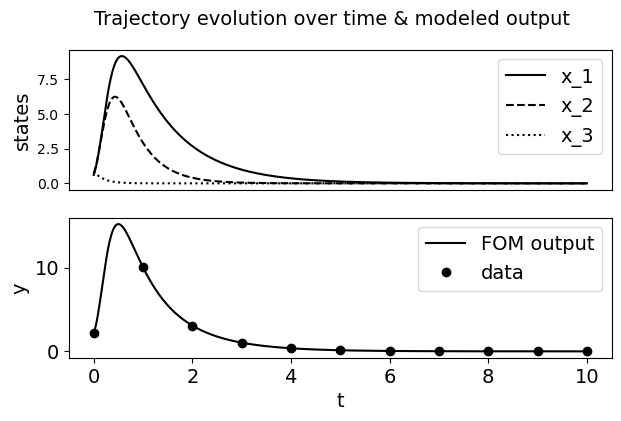

In [240]:
fig = plt.figure(figsize=(7,4))
fig.suptitle('Trajectory evolution over time & modeled output', fontsize=14)

# First plot: all states
ax = fig.add_subplot(2,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], 'k-', label='x_1')
ax.plot(traj_time, FOM_x_trajs[k][:,1], 'k--', label='x_2')
ax.plot(traj_time, FOM_x_trajs[k][:,2], 'k:', label='x_3')
ax.set_ylabel('states', fontsize=14)
ax.set_xticks([])
ax.legend(fontsize=14)

# Second plot: output
ax = fig.add_subplot(2,1,2)
ax.plot(traj_time, FOM_y_trajs[k][:,0], 'k-', label='FOM output')
ax.plot(t_data, y_traj_data[k][:,0], 'ko', label='data')
ax.set_ylabel('y', fontsize=14)
ax.set_xlabel('t', fontsize=14)
ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize=14)

k = (k + 1) % n_traj
plt.show()

In [241]:
# Generate 30 test initial conditions in the extrapolation range [1.0, 1.5].
np.random.seed(24)
n_traj_test = 30

Initial_condition_test = [np.random.uniform(1, 1.5, size=n_states) for _ in range(n_traj_test)]

In [242]:
# Generate 30 test initial conditions without extrapolation in the range [0.5, 1.0].
np.random.seed(24)
n_traj_test = 30

Initial_condition_test = [np.random.uniform(0.5, 1, size=n_states) for _ in range(n_traj_test)]

In [243]:
# System Setup
n = A_FOM.shape[0]
m = B_FOM.shape[1]
p = C_FOM.shape[0]

Q = np.eye(p)
# A large R penalizes control effort strongly.
R = 1e2 * np.eye(m)

# Time grid: Left Gauss-Radau nodes and weights.
t0, tf = 0.0, 10
N = 200
t, w = gauss_radau_left(N, a=t0, b=tf)

def pack_u(U):
    return U.reshape(-1)

def unpack_u(u_vec):
    return u_vec.reshape(N, m)

def make_u_fun(u_vec):
    U = unpack_u(u_vec)
    return BarycentricInterpolator(t, U, axis=0)

# Forward simulation of the nonlinear FOM.
# Use dense output so the solution can be evaluated at the quadrature nodes.
def forward_trajectory(u_vec,x0):
    u_fun = make_u_fun(u_vec)

    def f(tq, x):
        return FOM(x, u_fun(tq))  # Nonlinear dynamics.

    sol = solve_ivp(f, (t0, tf), x0, dense_output=True, method='RK45', rtol=rtol,atol=atol)
    return sol.sol  # Return the continuous solution x(t).

# Cost functional.
def total_cost(u_vec, X):
    U = unpack_u(u_vec)
    Y = (C_FOM @ X.T).T
    stage_y = np.einsum('ij,ij->i', Y @ Q, Y)
    stage_u = np.einsum('ij,ij->i', U @ R, U)
    J = np.dot(w, stage_y + stage_u)
    return J

# Gradient using the adjoint method.
def gradient(u_vec, X, return_adj=False):
    u_fun = make_u_fun(u_vec)

    def adj_rhs(tq, p):
        xq = X(tq)
        return - d_FOM_adj(xq, u_fun(tq), p) - 2 * d_FOM_obs_adj(xq, Q @ FOM_obs(xq))

    pT = np.zeros(n)
    sol = solve_ivp(lambda tq, p: adj_rhs(tq, p),
                    (tf, t0), pT, dense_output=True,
                    method='RK45', rtol=rtol, atol=atol)
    P = sol.sol(t).T  # Evaluate the continuous adjoint at the quadrature nodes.

    U = unpack_u(u_vec)
    BtP = np.array([B_FOM.T @ P[i] for i in range(len(P))])
    Gi = (BtP + 2.0 * (U @ R)) * w[:, None]

    if return_adj:
        return Gi.reshape(-1), P
    else:
        return Gi.reshape(-1)
    
# Objective and callbacks.
def objective_with_grad(u_vec,x0):
    X_fun = forward_trajectory(u_vec,x0)
    X = X_fun(t).T  # Evaluate the state trajectory at the quadrature nodes.
    J = total_cost(u_vec, X)
    g = gradient(u_vec, X_fun)
    return J, g

def fun_only(u_vec,x0):
    return objective_with_grad(u_vec,x0)[0]  # Return the cost.

def jac_only(u_vec,x0):
    return objective_with_grad(u_vec,x0)[1]  # Return the gradient with respect to the control parameters.

# Callback for logging iteration progress.
iteration_data = []

def callback(u_vec,x0):
    J, g = objective_with_grad(u_vec,x0)
    grad_norm = np.linalg.norm(g)
    iteration_data.append((len(iteration_data), J, grad_norm))
    print(f"Iter {len(iteration_data):3d}: Cost = {J:.6f}, ||grad|| = {grad_norm:.3e}")

In [244]:
def verify_adjoint_gradient(x0, N, m, t, forward_trajectory, gradient, total_cost, eps=1e-5):

    u_vec = np.random.randn(N * m)

    # Forward returns function and evaluate at quadrature nodes
    x_fun = forward_trajectory(u_vec, x0)
    X = x_fun(t).T

    # Adjoint gradient - pass function
    g_analytic = gradient(u_vec, x_fun)

    # Random direction
    v = np.random.randn(*u_vec.shape)
    v /= np.linalg.norm(v)

    adj_deriv = np.dot(g_analytic, v)

    # Cost at base point
    J0 = total_cost(u_vec, X)

    # Perturb control in the direction of v
    u_pert = u_vec + eps * v

    # Forward for perturbed control
    x_fun_pert = forward_trajectory(u_pert, x0)
    X_pert = x_fun_pert(t).T

    J1 = total_cost(u_pert, X_pert)

    # Finite difference check
    fd_deriv = (J1 - J0) / eps

    # Relative error
    rel_err = np.abs(adj_deriv - fd_deriv) / np.abs(fd_deriv)

    return rel_err, adj_deriv, fd_deriv

In [245]:
rel_err, adj_deriv, fd_deriv= verify_adjoint_gradient(x0, N, m, t, forward_trajectory, gradient, total_cost, eps=1e-5)
print("\nAdjoint Gradient Verification")
print(f"Adjoint directional derivative : {adj_deriv:.6e}")
print(f"Finite diff directional deriv. : {fd_deriv:.6e}")
print(f"Ratio (adj/fd)                 : {adj_deriv/(fd_deriv + 1e-12):.6f}")
print(f"Relative error                 : {rel_err:.6e}")

# Use a small relative error threshold.
if rel_err < 1e-3:
        print("✅ Gradient check PASSED")
else:
        print("⚠️ Gradient check FAILED")


Adjoint Gradient Verification
Adjoint directional derivative : -9.373342e+00
Finite diff directional deriv. : -9.374293e+00
Ratio (adj/fd)                 : 0.999899
Relative error                 : 1.014903e-04
✅ Gradient check PASSED


Iter   1: Cost = 97.175265, ||grad|| = 5.316e+01
Iter   2: Cost = 83.419271, ||grad|| = 5.301e+01
Iter   3: Cost = 83.152384, ||grad|| = 4.696e+01
Iter   4: Cost = 80.607955, ||grad|| = 4.473e+01
Iter   5: Cost = 75.918280, ||grad|| = 4.094e+01
Iter   6: Cost = 68.464749, ||grad|| = 3.385e+01
Iter   7: Cost = 59.966849, ||grad|| = 2.359e+01
Iter   8: Cost = 54.067818, ||grad|| = 1.524e+01
Iter   9: Cost = 50.767612, ||grad|| = 1.061e+01
Iter  10: Cost = 48.786952, ||grad|| = 7.841e+00
Iter  11: Cost = 47.557743, ||grad|| = 5.994e+00
Iter  12: Cost = 46.676216, ||grad|| = 4.475e+00
Iter  13: Cost = 46.194998, ||grad|| = 3.660e+00
Iter  14: Cost = 45.863427, ||grad|| = 2.734e+00
Iter  15: Cost = 45.725027, ||grad|| = 2.397e+00
Iter  16: Cost = 45.581538, ||grad|| = 1.686e+00
Iter  17: Cost = 45.519246, ||grad|| = 1.588e+00
Iter  18: Cost = 45.458106, ||grad|| = 1.050e+00
Iter  19: Cost = 45.445160, ||grad|| = 1.051e+00
Iter  20: Cost = 45.425752, ||grad|| = 8.045e-01
Iter  21: Cost = 45.

/opt/anaconda3/envs/control-env/lib/python3.11/site-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


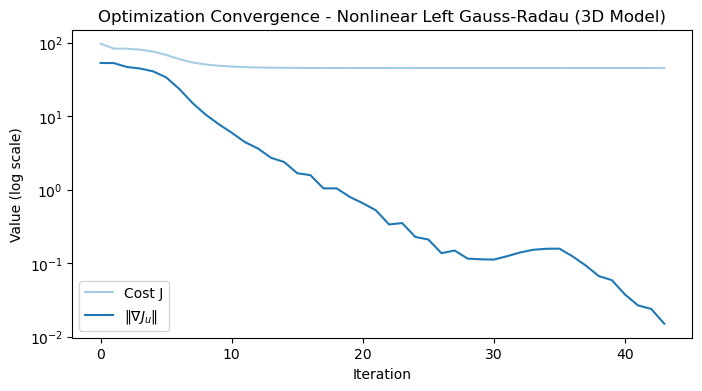

In [246]:
# Optimization
U0 = 0 * np.ones((N, m))   # Initial guess (zeros)
u0 = pack_u(U0)

# Minimize the cost function while passing the cost and gradient to BFGS.
res = minimize(fun_only, u0, args=(x0,), jac=jac_only, method='BFGS',
               tol=1e-6,
               options=dict(maxiter=800, gtol=1e-12, disp=True),
               callback=lambda u: callback(u, x0))

# Check why optimization stopped.
print("\n--- Optimizer Status ---")
print("Success:", res.success)
print("Message:", res.message)
print("Status:", res.status)
print("Iterations:", res.nit)
print("Function evaluations:", res.nfev)
print("Gradient evaluations:", res.njev)
print("Final gradient norm:", np.linalg.norm(res.jac))

# Store the optimal control and trajectory.
u_star = unpack_u(res.x)
X_star_fun = forward_trajectory(res.x,x0)
X = X_star_fun(t).T  # Evaluate the optimal state trajectory at the quadrature nodes.
J_star = total_cost(res.x, X)
Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)
print("\nOptimization complete.")
print("Final cost J* =", J_star)

# Plot convergence.
if iteration_data:
    iters, costs, grads = zip(*iteration_data)
    plt.figure(figsize=(8,4))
    plt.semilogy(iters, costs, label="Cost J")
    plt.semilogy(iters, grads, label=r"$\|\nabla J_u\|$")
    plt.xlabel("Iteration")
    plt.ylabel("Value (log scale)")
    plt.title("Optimization Convergence - Nonlinear Left Gauss-Radau (3D Model)")
    plt.legend()
    plt.minorticks_off()
    plt.grid(False)
    plt.show()

In [255]:
custom_colors = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c", "#000000"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=custom_colors)

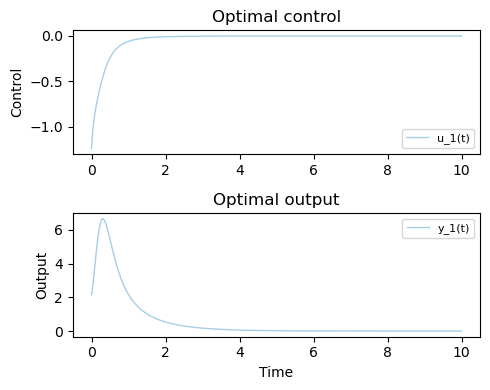

In [266]:
# Plot the optimal control and output trajectories using Left Gauss-Radau quadrature for the nonlinear 3D model.
Y_star = (C_FOM @ X.T).T
fig, axes = plt.subplots(2, 1, figsize=(5,4))

for j in range(u_star.shape[1]):
    axes[0].plot(t, u_star[:, j], label=f"u_{j+1}(t)", linewidth=1.0)
axes[0].set_ylabel("Control")
axes[0].set_title("Optimal control")
axes[0].legend(fontsize=8)
axes[0].grid(False)

for j in range(Y_star.shape[1]):
    axes[1].plot(t, Y_star[:, j], label=f"y_{j+1}(t)", linewidth=1.0)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Output")
axes[1].set_title("Optimal output")
axes[1].legend(fontsize=8)
axes[1].grid(False)

plt.tight_layout()
plt.show()